# Part 2 — Exploratory Data Analysis with Apache Spark
**Dataset:** `data/bank.csv` — 4,521 bank clients contacted in a term-deposit marketing campaign.

Spark runs here in **local mode with 4 worker threads** (`local[4]`). The code is exactly what would run on a
real cluster: the DataFrame is split into **partitions**, each partition is processed by a separate task in
parallel, and only small aggregated results come back to the driver. Changing `.master(...)` to a YARN or
standalone cluster URL is the only change needed to scale out.

In [1]:
import os, sys, time
# Spark needs Java 17; point to Homebrew's JDK if JAVA_HOME is not already set
os.environ.setdefault("JAVA_HOME", "/opt/homebrew/opt/openjdk@17/libexec/openjdk.jdk/Contents/Home")
os.environ["PYSPARK_PYTHON"] = sys.executable          # workers use this venv's Python
os.environ.setdefault("SPARK_LOCAL_IP", "127.0.0.1")    # single machine: bind to localhost
os.chdir(os.path.dirname(os.path.abspath("__file__")) if os.path.exists("data") else "..")

from pyspark.sql import SparkSession, functions as F, types as T

spark = (SparkSession.builder
         .appName("Bank-EDA")
         .master("local[4]")                          # 4 worker threads = 4 parallel tasks
         .config("spark.driver.memory", "2g")
         .config("spark.sql.shuffle.partitions", "8")  # small data -> fewer shuffle partitions
         .config("spark.hadoop.fs.defaultFS", "file:///")  # read local files even if HADOOP_CONF_DIR is set
         .config("spark.ui.showConsoleProgress", "false")
         .getOrCreate())
spark.sparkContext.setLogLevel("ERROR")
DATA = "data/bank.csv"
print("Spark", spark.version, "| master:", spark.sparkContext.master,
      "| default parallelism:", spark.sparkContext.defaultParallelism)
print("Spark UI (while this notebook runs): http://localhost:4040")

Using Spark's default log4j profile: org/apache/spark/log4j2-defaults.properties
Setting default log level to "WARN".
To adjust logging level use sc.setLogLevel(newLevel). For SparkR, use setLogLevel(newLevel).


26/11/25 11:00:47 WARN NativeCodeLoader: Unable to load native-hadoop library for your platform... using builtin-java classes where applicable


Spark 4.0.1 | master: local[4] | default parallelism: 4
Spark UI (while this notebook runs): http://localhost:4040


## 1. Data loading and basic inspection

In [2]:
df = (spark.read
        .option("header", True)
        .option("inferSchema", True)
        .csv(DATA))
df.cache()                                  # reused many times below -> keep it in memory
print("rows:", df.count(), "| columns:", len(df.columns), "| partitions:", df.rdd.getNumPartitions())
df.show(5)

rows: 4521 | columns: 17 | partitions: 1
+---+-----------+-------+---------+-------+-------+-------+----+--------+---+-----+--------+--------+-----+--------+--------+---+
|age|        job|marital|education|default|balance|housing|loan| contact|day|month|duration|campaign|pdays|previous|poutcome|  y|
+---+-----------+-------+---------+-------+-------+-------+----+--------+---+-----+--------+--------+-----+--------+--------+---+
| 30| unemployed|married|  primary|     no|   1787|     no|  no|cellular| 19|  oct|      79|       1|   -1|       0| unknown| no|
| 33|   services|married|secondary|     no|   4789|    yes| yes|cellular| 11|  may|     220|       1|  339|       4| failure| no|
| 35| management| single| tertiary|     no|   1350|    yes|  no|cellular| 16|  apr|     185|       1|  330|       1| failure| no|
| 30| management|married| tertiary|     no|   1476|    yes| yes| unknown|  3|  jun|     199|       4|   -1|       0| unknown| no|
| 59|blue-collar|married|secondary|     no|      

In [3]:
df.printSchema()

root
 |-- age: integer (nullable = true)
 |-- job: string (nullable = true)
 |-- marital: string (nullable = true)
 |-- education: string (nullable = true)
 |-- default: string (nullable = true)
 |-- balance: integer (nullable = true)
 |-- housing: string (nullable = true)
 |-- loan: string (nullable = true)
 |-- contact: string (nullable = true)
 |-- day: integer (nullable = true)
 |-- month: string (nullable = true)
 |-- duration: integer (nullable = true)
 |-- campaign: integer (nullable = true)
 |-- pdays: integer (nullable = true)
 |-- previous: integer (nullable = true)
 |-- poutcome: string (nullable = true)
 |-- y: string (nullable = true)



In [4]:
num_cols = [c for c, t in df.dtypes if t == "int"]
df.select(num_cols).summary("count", "mean", "stddev", "min", "25%", "50%", "75%", "max").show()

+-------+------------------+------------------+------------------+------------------+------------------+------------------+------------------+
|summary|               age|           balance|               day|          duration|          campaign|             pdays|          previous|
+-------+------------------+------------------+------------------+------------------+------------------+------------------+------------------+
|  count|              4521|              4521|              4521|              4521|              4521|              4521|              4521|
|   mean| 41.17009511170095|1422.6578190665782|15.915284229152842|263.96129174961294| 2.793629727936297|39.766644547666445|0.5425790754257908|
| stddev|10.576210958711263|3009.6381424673395| 8.247667327229934|259.85663262468216|3.1098066601885823|100.12112444301656|1.6935623506071211|
|    min|                19|             -3313|                 1|                 4|                 1|                -1|                 0|

In [5]:
# Missing values check (Spark computes all column counts in ONE distributed pass)
df.select([F.sum(F.col(c).isNull().cast("int")).alias(c) for c in df.columns]).show()
# 'unknown' is used instead of null for categorical columns:
df.select([F.sum((F.col(c) == "unknown").cast("int")).alias(c)
           for c, t in df.dtypes if t == "string"]).show()

+---+---+-------+---------+-------+-------+-------+----+-------+---+-----+--------+--------+-----+--------+--------+---+
|age|job|marital|education|default|balance|housing|loan|contact|day|month|duration|campaign|pdays|previous|poutcome|  y|
+---+---+-------+---------+-------+-------+-------+----+-------+---+-----+--------+--------+-----+--------+--------+---+
|  0|  0|      0|        0|      0|      0|      0|   0|      0|  0|    0|       0|       0|    0|       0|       0|  0|
+---+---+-------+---------+-------+-------+-------+----+-------+---+-----+--------+--------+-----+--------+--------+---+



+---+-------+---------+-------+-------+----+-------+-----+--------+---+
|job|marital|education|default|housing|loan|contact|month|poutcome|  y|
+---+-------+---------+-------+-------+----+-------+-----+--------+---+
| 38|      0|      187|      0|      0|   0|   1324|    0|    3705|  0|
+---+-------+---------+-------+-------+----+-------+-----+--------+---+



## 2. Data filtering and column operations

In [6]:
THRESHOLD = 1000
rich = df.filter(F.col("balance") > THRESHOLD)
print(f"clients with balance > {THRESHOLD}: {rich.count()} of {df.count()}")
rich.select("age", "job", "marital", "balance", "y").orderBy(F.desc("balance")).show(5)

clients with balance > 1000: 1481 of 4521
+---+------------+-------+-------+---+
|age|         job|marital|balance|  y|
+---+------------+-------+-------+---+
| 60|     retired|married|  71188| no|
| 42|entrepreneur|married|  42045| no|
| 43|  technician| single|  27733| no|
| 36|  management|married|  27359| no|
| 57|  technician|married|  27069| no|
+---+------------+-------+-------+---+
only showing top 5 rows


In [7]:
# month is text ('jan'..'dec') -> month number -> quarter
months = ["jan","feb","mar","apr","may","jun","jul","aug","sep","oct","nov","dec"]
month_map = F.create_map(*[x for i, m in enumerate(months, 1) for x in (F.lit(m), F.lit(i))])

df = (df.withColumn("month_num", month_map[F.col("month")])
        .withColumn("quarter", F.concat(F.lit("Q"), F.ceil(F.col("month_num") / 3).cast("int"))))
df.select("month", "month_num", "quarter").distinct().orderBy("month_num").show(12)
df.groupBy("quarter").count().orderBy("quarter").show()

+-----+---------+-------+
|month|month_num|quarter|
+-----+---------+-------+
|  jan|        1|     Q1|
|  feb|        2|     Q1|
|  mar|        3|     Q1|
|  apr|        4|     Q2|
|  may|        5|     Q2|
|  jun|        6|     Q2|
|  jul|        7|     Q3|
|  aug|        8|     Q3|
|  sep|        9|     Q3|
|  oct|       10|     Q4|
|  nov|       11|     Q4|
|  dec|       12|     Q4|
+-----+---------+-------+

+-------+-----+
|quarter|count|
+-------+-----+
|     Q1|  419|
|     Q2| 2222|
|     Q3| 1391|
|     Q4|  489|
+-------+-----+



## 3. GroupBy and aggregation

In [8]:
(df.groupBy("job")
   .agg(F.count("*").alias("clients"),
        F.round(F.avg("balance"), 2).alias("avg_balance"),
        F.median("age").alias("median_age"))
   .orderBy(F.desc("avg_balance"))
   .show())

+-------------+-------+-----------+----------+
|          job|clients|avg_balance|median_age|
+-------------+-------+-----------+----------+
|      retired|    230|    2319.19|      59.0|
|    housemaid|    112|     2083.8|      49.0|
|   management|    969|    1766.93|      38.0|
| entrepreneur|    168|    1645.13|      41.0|
|      student|     84|    1543.82|      26.0|
|      unknown|     38|    1501.71|      49.5|
|self-employed|    183|    1392.41|      40.0|
|   technician|    768|     1331.0|      38.0|
|       admin.|    478|    1226.74|      38.0|
|     services|    417|    1103.96|      37.0|
|   unemployed|    128|    1089.42|      41.0|
|  blue-collar|    946|    1085.16|      39.0|
+-------------+-------+-----------+----------+



In [9]:
(df.filter(F.col("y") == "yes")
   .groupBy("marital").count().withColumnRenamed("count", "subscribed_clients")
   .orderBy(F.desc("subscribed_clients")).show())

+--------+------------------+
| marital|subscribed_clients|
+--------+------------------+
| married|               277|
|  single|               167|
|divorced|                77|
+--------+------------------+



In [10]:
# How Spark actually executes a groupBy: partial aggregation inside each partition,
# then a shuffle (Exchange) that brings each job's partial sums together, then the final aggregation.
df.groupBy("job").agg(F.avg("balance")).explain()

== Physical Plan ==
AdaptiveSparkPlan isFinalPlan=false
+- HashAggregate(keys=[job#18], functions=[avg(balance#22)])
   +- Exchange hashpartitioning(job#18, 8), ENSURE_REQUIREMENTS, [plan_id=707]
      +- HashAggregate(keys=[job#18], functions=[partial_avg(balance#22)])
         +- InMemoryTableScan [job#18, balance#22]
               +- InMemoryRelation [age#17, job#18, marital#19, education#20, default#21, balance#22, housing#23, loan#24, contact#25, day#26, month#27, duration#28, campaign#29, pdays#30, previous#31, poutcome#32, y#33], StorageLevel(disk, memory, deserialized, 1 replicas)
                     +- FileScan csv [age#17,job#18,marital#19,education#20,default#21,balance#22,housing#23,loan#24,contact#25,day#26,month#27,duration#28,campaign#29,pdays#30,previous#31,poutcome#32,y#33] Batched: false, DataFilters: [], Format: CSV, Location: InMemoryFileIndex(1 paths)[file:/Users/pranati/bank-distributed-ml/data/bank.csv], PartitionFilters: [], PushedFilters: [], ReadSchema: stru

## 4. UDF to categorise age groups

In [11]:
@F.udf(returnType=T.StringType())
def age_group(age):
    if age is None:
        return None
    if age < 30:
        return "<30"
    if age <= 60:
        return "30-60"
    return ">60"

df = df.withColumn("age_group", age_group("age"))
df.groupBy("age_group").agg(F.count("*").alias("clients"),
                            F.round(F.avg("balance"), 2).alias("avg_balance"),
                            F.round(100 * F.avg((F.col("y") == "yes").cast("int")), 2).alias("subscribed_pct")
                           ).orderBy("age_group").show()

+---------+-------+-----------+--------------+
|age_group|clients|avg_balance|subscribed_pct|
+---------+-------+-----------+--------------+
|    30-60|   3912|    1426.88|          10.2|
|      <30|    482|     1058.1|         15.35|
|      >60|    127|    2676.35|          37.8|
+---------+-------+-----------+--------------+



> A Python UDF ships every row to a Python worker, which is slower than built-in functions.
> The same column using only Spark expressions (runs inside the JVM, can be optimised by Catalyst):

In [12]:
df_builtin = df.withColumn("age_group_builtin",
    F.when(F.col("age") < 30, "<30").when(F.col("age") <= 60, "30-60").otherwise(">60"))
print("UDF and built-in versions agree:",
      df_builtin.filter(F.col("age_group") != F.col("age_group_builtin")).count() == 0)

UDF and built-in versions agree: True


## 5. Advanced data transformations

In [13]:
(df.groupBy("education")
   .agg(F.count("*").alias("clients"),
        F.sum((F.col("y") == "yes").cast("int")).alias("subscribed"))
   .withColumn("subscription_rate_pct", F.round(100 * F.col("subscribed") / F.col("clients"), 2))
   .orderBy(F.desc("subscription_rate_pct")).show())

+---------+-------+----------+---------------------+
|education|clients|subscribed|subscription_rate_pct|
+---------+-------+----------+---------------------+
| tertiary|   1350|       193|                 14.3|
|secondary|   2306|       245|                10.62|
|  unknown|    187|        19|                10.16|
|  primary|    678|        64|                 9.44|
+---------+-------+----------+---------------------+



In [14]:
(df.groupBy("job")
   .agg(F.count("*").alias("clients"),
        F.sum((F.col("default") == "yes").cast("int")).alias("defaulters"))
   .withColumn("default_rate_pct", F.round(100 * F.col("defaulters") / F.col("clients"), 2))
   .orderBy(F.desc("default_rate_pct"))
   .limit(3).show())

+-------------+-------+----------+----------------+
|          job|clients|defaulters|default_rate_pct|
+-------------+-------+----------+----------------+
| entrepreneur|    168|         7|            4.17|
|   unemployed|    128|         3|            2.34|
|self-employed|    183|         4|            2.19|
+-------------+-------+----------+----------------+



## 6. String manipulation

In [15]:
df = (df.withColumn("job_marital", F.concat_ws("_", "job", "marital"))
        .withColumn("contact", F.upper("contact")))
df.select("job", "marital", "job_marital", "contact").show(5, truncate=False)
df.groupBy("job_marital").count().orderBy(F.desc("count")).show(5, truncate=False)

+-----------+-------+-------------------+--------+
|job        |marital|job_marital        |contact |
+-----------+-------+-------------------+--------+
|unemployed |married|unemployed_married |CELLULAR|
|services   |married|services_married   |CELLULAR|
|management |single |management_single  |CELLULAR|
|management |married|management_married |UNKNOWN |
|blue-collar|married|blue-collar_married|UNKNOWN |
+-----------+-------+-------------------+--------+
only showing top 5 rows
+-------------------+-----+
|job_marital        |count|
+-------------------+-----+
|blue-collar_married|693  |
|management_married |557  |
|technician_married |411  |
|management_single  |293  |
|technician_single  |268  |
+-------------------+-----+
only showing top 5 rows


## 7. Data visualisation
Only the **small aggregated result** is converted to pandas — the heavy work stays in Spark.
(Converting a full billion-row table with `toPandas()` would crash the driver.)

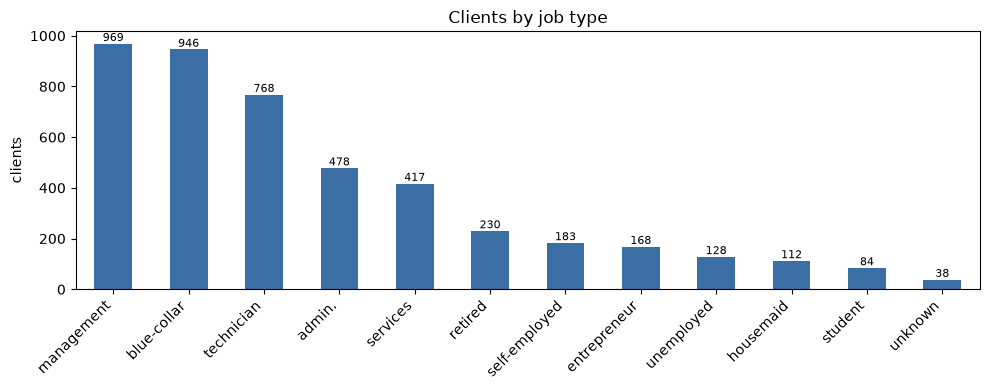

In [16]:
import matplotlib.pyplot as plt
os.makedirs("docs/figures", exist_ok=True)

job_counts = df.groupBy("job").count().orderBy(F.desc("count")).toPandas()
ax = job_counts.plot.bar(x="job", y="count", legend=False, figsize=(10, 4), color="#3b6ea5")
ax.set_title("Clients by job type"); ax.set_xlabel(""); ax.set_ylabel("clients")
for p in ax.patches:
    ax.annotate(int(p.get_height()), (p.get_x() + p.get_width() / 2, p.get_height()),
                ha="center", va="bottom", fontsize=8)
plt.xticks(rotation=45, ha="right"); plt.tight_layout()
plt.savefig("docs/figures/clients_by_job.png", dpi=120); plt.show()

In [17]:
# The task also asks for converting the Spark DataFrame itself to pandas (fine at 4.5k rows)
pdf = df.toPandas()
print(type(pdf), pdf.shape)
pdf.head()

<class 'pandas.DataFrame'> (4521, 21)


,age,job,marital,education,default,balance,housing,loan,contact,day,...,duration,campaign,pdays,previous,poutcome,y,month_num,quarter,age_group,job_marital
0,30,unemployed,married,primary,no,1787,no,no,CELLULAR,19,...,79,1,-1,0,unknown,no,10,Q4,30-60,unemployed_married
1,33,services,married,secondary,no,4789,yes,yes,CELLULAR,11,...,220,1,339,4,failure,no,5,Q2,30-60,services_married
2,35,management,single,tertiary,no,1350,yes,no,CELLULAR,16,...,185,1,330,1,failure,no,4,Q2,30-60,management_single
3,30,management,married,tertiary,no,1476,yes,yes,UNKNOWN,3,...,199,4,-1,0,unknown,no,6,Q2,30-60,management_married
4,59,blue-collar,married,secondary,no,0,yes,no,UNKNOWN,5,...,226,1,-1,0,unknown,no,5,Q2,30-60,blue-collar_married


## 8. Complex queries for insights

In [18]:
monthly = (df.groupBy("month", "month_num")
             .agg(F.count("*").alias("contacts"),
                  F.round(100 * F.avg((F.col("y") == "yes").cast("int")), 2).alias("success_rate_pct"))
             .orderBy(F.desc("contacts")))
monthly.show(12)
top = monthly.first()
print(f"Busiest month: {top['month']} with {top['contacts']} contacts, success rate {top['success_rate_pct']}%")

+-----+---------+--------+----------------+
|month|month_num|contacts|success_rate_pct|
+-----+---------+--------+----------------+
|  may|        5|    1398|            6.65|
|  jul|        7|     706|            8.64|
|  aug|        8|     633|           12.48|
|  jun|        6|     531|           10.36|
|  nov|       11|     389|           10.03|
|  apr|        4|     293|           19.11|
|  feb|        2|     222|           17.12|
|  jan|        1|     148|           10.81|
|  oct|       10|      80|           46.25|
|  sep|        9|      52|           32.69|
|  mar|        3|      49|           42.86|
|  dec|       12|      20|            45.0|
+-----+---------+--------+----------------+

Busiest month: may with 1398 contacts, success rate 6.65%


In [19]:
(df.groupBy("y")
   .agg(F.count("*").alias("clients"),
        F.round(F.avg("duration"), 1).alias("avg_duration_sec"),
        F.median("duration").alias("median_duration_sec"))
   .show())

+---+-------+----------------+-------------------+
|  y|clients|avg_duration_sec|median_duration_sec|
+---+-------+----------------+-------------------+
| no|   4000|           226.3|              167.0|
|yes|    521|           552.7|              442.0|
+---+-------+----------------+-------------------+



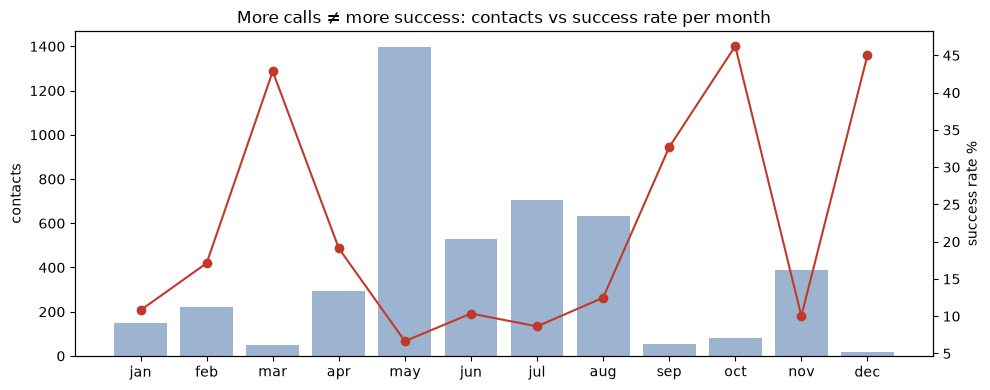

In [20]:
mp = monthly.orderBy("month_num").toPandas()
fig, ax1 = plt.subplots(figsize=(10, 4))
ax1.bar(mp["month"], mp["contacts"], color="#9db4d0", label="contacts")
ax1.set_ylabel("contacts")
ax2 = ax1.twinx()
ax2.plot(mp["month"], mp["success_rate_pct"], color="#c0392b", marker="o", label="success rate %")
ax2.set_ylabel("success rate %")
ax1.set_title("More calls ≠ more success: contacts vs success rate per month")
fig.tight_layout(); plt.savefig("docs/figures/month_contacts_vs_success.png", dpi=120); plt.show()

## 9. Correlation between age and balance

In [21]:
r = df.stat.corr("age", "balance")
print(f"Pearson correlation(age, balance) = {r:.4f}")
print("=> very weak positive linear relationship" if abs(r) < 0.2 else "")

Pearson correlation(age, balance) = 0.0838
=> very weak positive linear relationship


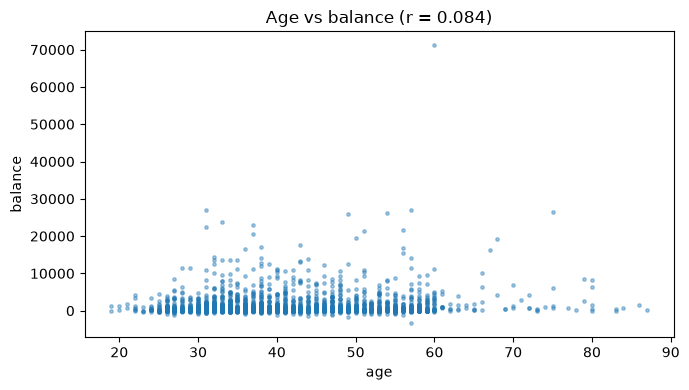

In [22]:
sample = df.select("age", "balance").sample(fraction=0.5, seed=1).toPandas()
plt.figure(figsize=(7, 4))
plt.scatter(sample["age"], sample["balance"], s=6, alpha=0.4)
plt.title(f"Age vs balance (r = {r:.3f})"); plt.xlabel("age"); plt.ylabel("balance")
plt.tight_layout(); plt.savefig("docs/figures/age_vs_balance.png", dpi=120); plt.show()

## 10. Exploring loan defaults

+-------+-----+-----+
|default|count|  pct|
+-------+-----+-----+
|     no| 4445|98.32|
|    yes|   76| 1.68|
+-------+-----+-----+



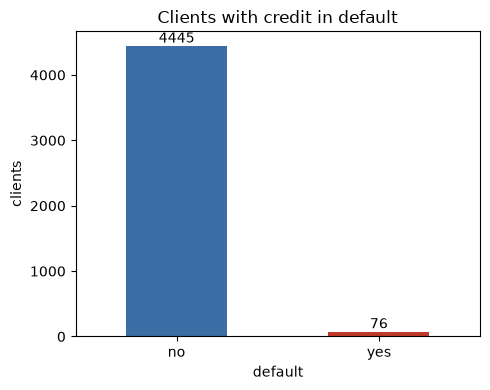

In [23]:
defaults = (df.groupBy("default").count()
              .withColumn("pct", F.round(100 * F.col("count") / F.sum("count").over(
                  __import__("pyspark.sql.window", fromlist=["Window"]).Window.partitionBy()), 2)))
defaults.show()
dp = defaults.toPandas()
ax = dp.plot.bar(x="default", y="count", legend=False, color=["#3b6ea5", "#c0392b"], figsize=(5, 4))
ax.set_title("Clients with credit in default"); ax.set_xlabel("default"); ax.set_ylabel("clients")
for p in ax.patches:
    ax.annotate(int(p.get_height()), (p.get_x() + p.get_width() / 2, p.get_height()), ha="center", va="bottom")
plt.xticks(rotation=0); plt.tight_layout(); plt.savefig("docs/figures/defaults.png", dpi=120); plt.show()

## 11. Contact method analysis

In [24]:
(df.groupBy("contact")
   .agg(F.count("*").alias("clients"),
        F.sum((F.col("y") == "yes").cast("int")).alias("subscribed"))
   .withColumn("success_rate_pct", F.round(100 * F.col("subscribed") / F.col("clients"), 2))
   .orderBy(F.desc("success_rate_pct")).show())

+---------+-------+----------+----------------+
|  contact|clients|subscribed|success_rate_pct|
+---------+-------+----------+----------------+
|TELEPHONE|    301|        44|           14.62|
| CELLULAR|   2896|       416|           14.36|
|  UNKNOWN|   1324|        61|            4.61|
+---------+-------+----------+----------------+



## 12. Data processing with Spark SQL

In [25]:
df.createOrReplaceTempView("bank")
spark.sql('''
    SELECT age_group,
           COUNT(*)                AS clients,
           ROUND(AVG(balance), 2)  AS avg_balance
    FROM bank
    GROUP BY age_group
    ORDER BY avg_balance DESC
''').show()

+---------+-------+-----------+
|age_group|clients|avg_balance|
+---------+-------+-----------+
|      >60|    127|    2676.35|
|    30-60|   3912|    1426.88|
|      <30|    482|     1058.1|
+---------+-------+-----------+



In [26]:
spark.sql('''
    SELECT job, COUNT(*) AS clients, ROUND(AVG(balance), 2) AS avg_balance
    FROM bank
    GROUP BY job
    ORDER BY clients DESC
    LIMIT 5
''').show()

+-----------+-------+-----------+
|        job|clients|avg_balance|
+-----------+-------+-----------+
| management|    969|    1766.93|
|blue-collar|    946|    1085.16|
| technician|    768|     1331.0|
|     admin.|    478|    1226.74|
|   services|    417|    1103.96|
+-----------+-------+-----------+



## Key findings
* **Imbalanced target:** only ~11.5% of clients subscribed — accuracy alone will be misleading in Part 3.
* **Call duration** is the strongest signal: subscribers talk ~2.4× longer (553 s vs 226 s on average).
* **Previous success matters:** clients whose previous campaign outcome was `success` subscribe ~64% of the time.
* **May is the busiest month but the worst converter** (≈1,400 calls, ≈6.7% success), while low-volume
  months (Mar, Sep, Oct, Dec) convert at 33–46% — a sign of over-calling in peak months.
* **Retired clients** have the highest average balance and one of the highest subscription rates.
* **Age vs balance** correlation is ≈0.08 — almost no linear relationship.
* **Contact method:** telephone (14.6%) and cellular (14.4%) convert about equally; clients with an `unknown`
  contact type convert at only 4.6% — the channel being recorded at all is what matters.
* Defaults are rare (~1.7%), so default prediction would need resampling/class weights.

In [27]:
spark.stop()